Данные успешно загружены!
Размер датасета: (20640, 9)

Первые 5 строк:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2  

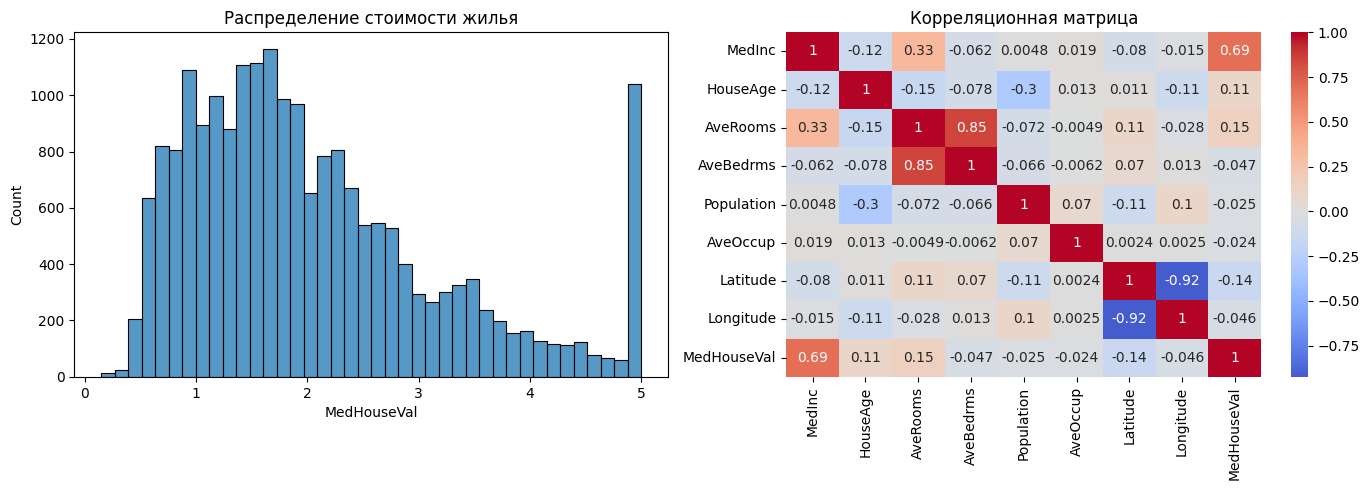


Размер train: (16512, 8)
Размер test: (4128, 8)

Результаты модели LinearRegression:
MAE:  0.5332
MSE:  0.5559
RMSE: 0.7456
R2:   0.5758

Примеры предсказаний (цены указаны в единицах датасета):
 Реальная цена  Предсказанная цена
         0.477               0.719
         0.458               1.764
         5.000               2.710
         2.186               2.839
         2.780               2.605
         1.587               2.012
         1.982               2.646
         1.575               2.169
         3.400               2.741
         4.466               3.916


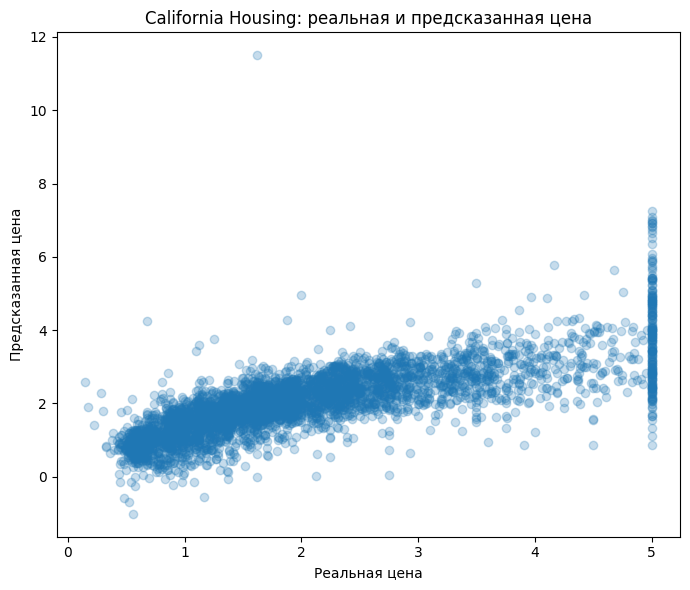

In [1]:
import tempfile
from pathlib import Path

from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def main():
    try:
        import matplotlib.pyplot as plt
        import pandas as pd
        import seaborn as sns
    except ImportError as error:
        raise SystemExit("Установите библиотеки: pip install pandas seaborn matplotlib") from error


    data_home = Path(tempfile.gettempdir()) / "belashevskiy_sklearn_data"
    data = fetch_california_housing(data_home=data_home, as_frame=True)
    df = data.frame
    print("Данные успешно загружены!")
    print("Размер датасета:", df.shape)


    print("\nПервые 5 строк:")
    print(df.head())
    print("\nИнформация о столбцах:")
    df.info()
    print("\nОписательная статистика:")
    print(df.describe())
    print("\nПропуски по столбцам:")
    print(df.isna().sum())


    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.histplot(df["MedHouseVal"], bins=40, ax=axes[0])
    axes[0].set_title("Распределение стоимости жилья")
    sns.heatmap(
        df.corr(numeric_only=True), annot=True, cmap="coolwarm", center=0, ax=axes[1]
    )
    axes[1].set_title("Корреляционная матрица")
    plt.tight_layout()
    plt.show()


    x = df.drop("MedHouseVal", axis=1)
    y = df["MedHouseVal"]
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42
    )
    print("\nРазмер train:", x_train.shape)
    print("Размер test:", x_test.shape)


    model = make_pipeline(StandardScaler(), LinearRegression())
    model.fit(x_train, y_train)
    predictions = model.predict(x_test)

    print("\nРезультаты модели LinearRegression:")
    print(f"MAE:  {mean_absolute_error(y_test, predictions):.4f}")
    print(f"MSE:  {mean_squared_error(y_test, predictions):.4f}")
    print(f"RMSE: {mean_squared_error(y_test, predictions) ** 0.5:.4f}")
    print(f"R2:   {r2_score(y_test, predictions):.4f}")


    comparison = pd.DataFrame(
        {"Реальная цена": y_test.iloc[:10].values, "Предсказанная цена": predictions[:10]}
    )
    print("\nПримеры предсказаний (цены указаны в единицах датасета):")
    print(comparison.round(3).to_string(index=False))

    plt.figure(figsize=(7, 6))
    plt.scatter(y_test, predictions, alpha=0.25)
    plt.xlabel("Реальная цена")
    plt.ylabel("Предсказанная цена")
    plt.title("California Housing: реальная и предсказанная цена")
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()


- На California Housing (20 640 строк, 8 признаков) LinearRegression получила `MAE=0.5332`, `MSE=0.5559`, `RMSE=0.7456`, `R²=0.5758` на test из 4 128 строк.
- При `n` строках и `d` признаках масштабирование занимает `O(nd)`, матрица корреляций — `O(nd²)`, линейная регрессия методом наименьших квадратов — примерно `O(nd²+d³)` времени и `O(nd)` памяти. Предсказание для `m` строк — `O(md)`.